# Run GWR and SEM

Note:  used R implementation for mxGWR (gwr_r). 

follow; https://deepnote.com/app/carlos-mendez/PYTHON-GWR-and-MGWR-71dd8ba9-a3ea-4d28-9b20-41cc8a282b7a

In [1]:
from shapely.geometry import Point
import scanpy as sc
import anndata
# Check for NaN values
from statsmodels.stats.outliers_influence import variance_inflation_factor
import libpysal
from pysal.lib import weights
import seaborn as sns
from pysal.model import spreg
import pandas as pd
import numpy as np
import geopandas as gpd
from mgwr.gwr import GWR, MGWR
from mgwr.sel_bw import Sel_BW
import matplotlib.pyplot as plt
from scipy.stats import norm

In [2]:
adata = sc.read_h5ad("processed_data/xenium_lung_annotated.h5ad")

coords = adata.obsm["spatial"]

x = coords[:, 0]
y = coords[:, 1]

mask = (x < np.quantile(x, 0.5)) & (y < np.quantile(y, 0.5))

adata = adata[mask].copy()

/home/cenk/miniconda3/envs/spice_env/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:982: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


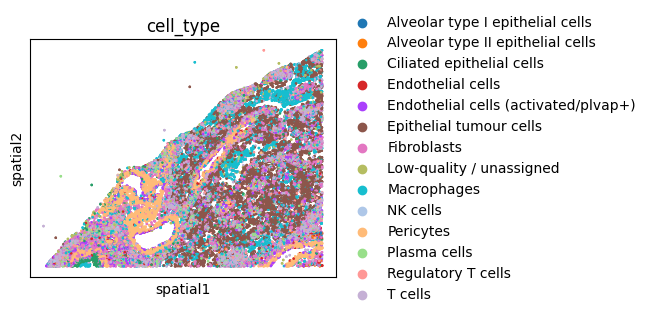

In [3]:
import squidpy as sq
sq.pl.spatial_scatter(adata, color="cell_type", shape=None, save="spatial_scatter_lung.pdf")

In [4]:
#read in X_pca_df; df with TME and CNV principal components
X_pca_df = pd.read_csv(
    "results/xenium_lung_5k_metadata_with_distances.csv"
)

In [5]:
# only keep the rows that are in adata.obs
X_pca_df = X_pca_df[X_pca_df["cell_id"].isin(adata.obs["cell_id"])]
X_pca_df.set_index("cell_id", inplace=True)

Adjust the dataframe for regression; different steps depending on what variables we want to include in the regression analysis

In [6]:
# Switch the sign of columns that start with "min"
X_pca_df.loc[:, X_pca_df.columns.str.startswith('min')] *= -1

# Normalize columns that start with "min"
X_pca_df.loc[:, X_pca_df.columns.str.startswith('min')] = (
    X_pca_df.loc[:, X_pca_df.columns.str.startswith('min')].apply(lambda x: (x - x.min()) / (x.max() - x.min()))
)

# Normalize columns that start with "PC"
X_pca_df.loc[:, X_pca_df.columns.str.startswith('PC')] = (
    X_pca_df.loc[:, X_pca_df.columns.str.startswith('PC')].apply(lambda x: (x - x.min()) / (x.max() - x.min()))
)
top_cells = [col for col in X_pca_df.columns if col.startswith('min') or col.startswith('PC')]
#add "Cluster" to top_cells if we want to regress this variable
#top_cells.append("Cluster")
#remove high colinearity variables
# top_cells = [col for col in top_cells if col != "PC2" and col != "min_distance_to_Endothelial.RGS5" and col != "min_distance_to_CAFs.MSC.iCAF.like"]

#remove all PC columns if we want to regress out just TME
top_cells = [col for col in top_cells if not col.startswith('PC')]
#remove all min columns if we want to regress just principal components
#top_cells = [col for col in top_cells if not col.startswith('min')]
X_pca_df_filtered = X_pca_df[top_cells]

In [7]:
filtered_df_x = X_pca_df_filtered.to_numpy()
u = X_pca_df["array_row"].values
v = X_pca_df["array_col"].values
y = X_pca_df["EMT_score"].values.reshape(-1, 1)

valid_mask = (
    np.isfinite(filtered_df_x).all(axis=1) &
    np.isfinite(y.ravel()) &
    np.isfinite(u) &
    np.isfinite(v)
)
print(f"Dropping {(~valid_mask).sum()} rows with NaN/Inf values ({valid_mask.sum()} rows remaining)")
filtered_df_x = filtered_df_x[valid_mask]
y = y[valid_mask]
u = u[valid_mask]
v = v[valid_mask]
coords = list(zip(u, v))

Dropping 33964 rows with NaN/Inf values (6289 rows remaining)


In [ ]:
# gwr_selector = Sel_BW(
#     coords,
#     y,
#     filtered_df_x,
#     fixed=False,
#     n_jobs=20
# ).search(bw_min=30)
# print(f"Optimal bandwidth: {gwr_selector}")
gwr_selector = 65.0

Optimal bandwidth: 65.0


In [9]:
gwr_results = GWR(coords, y, filtered_df_x, gwr_selector, n_jobs=20, hat_matrix=False).fit()

In [10]:
print(gwr_results.summary())

Model type                                                         Gaussian
Number of observations:                                                6289
Number of covariates:                                                    14

Global Regression Results
---------------------------------------------------------------------------
Residual sum of squares:                                              0.702
Log-likelihood:                                                   19692.554
AIC:                                                             -39357.108
AICc:                                                            -39355.032
BIC:                                                             -54883.945
R2:                                                                   0.227
Adj. R2:                                                              0.226

Variable                              Est.         SE  t(Est/SE)    p-value
------------------------------- ---------- ---------- ------

In [11]:
import numpy as np
from libpysal.weights import Queen
from spreg import GM_Error, ML_Error
import pandas as pd
from libpysal.weights import KNN

In [12]:
w = KNN.from_array(coords, k=16)
w.transform = 'r'
w = w.sparse
X = np.array(filtered_df_x)
y = np.array(y).reshape(-1, 1)
sem_model = GM_Error(y, X, w=w)
print(sem_model.summary)

GM_Error
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: GM SPATIALLY WEIGHTED LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     unknown
Dependent Variable  :     dep_var                Number of Observations:        6289
Mean dependent var  :     -0.0052                Number of Variables   :          14
S.D. dependent var  :      0.0120                Degrees of Freedom    :        6275
Pseudo R-squared    :      0.1939

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------------------------------------------------------
            CONSTANT        -0.06366         0.00645        -9.86899         0.00000
               var_1        -0.01025         0.00524        -1.95499         0.05058
               var_2         

In [13]:
#get attributes of sem_model
residuals = sem_model.u
#save residuals
np.save("results/residuals_sem_lung.npy", residuals)

In [14]:
print(sem_model.summary)

REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: GM SPATIALLY WEIGHTED LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     unknown
Dependent Variable  :     dep_var                Number of Observations:        6289
Mean dependent var  :     -0.0052                Number of Variables   :          14
S.D. dependent var  :      0.0120                Degrees of Freedom    :        6275
Pseudo R-squared    :      0.1939

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------------------------------------------------------
            CONSTANT        -0.06366         0.00645        -9.86899         0.00000
               var_1        -0.01025         0.00524        -1.95499         0.05058
               var_2         0.00462  

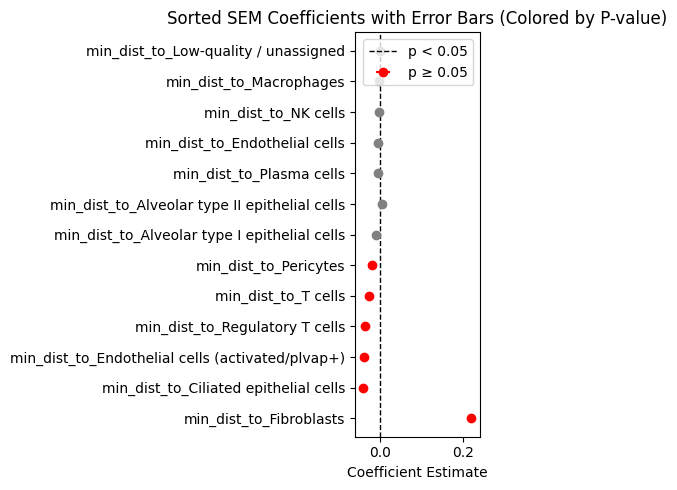

In [15]:
# Define predictor labels excluding const and lambda
predictor_labels = list(X_pca_df_filtered.columns)
# Extract coefficients, standard errors, and calculate z-scores excluding const and lambda
coefficients = sem_model.betas.flatten()[1:-1]  # Exclude intercept and lambda
std_errors = sem_model.std_err.flatten()[1:]  # Exclude intercept


# Calculate p-values from z-scores
z_scores = coefficients / std_errors
p_values = 2 * (1 - norm.cdf(np.abs(z_scores)))

if len(predictor_labels) != len(coefficients):
    raise ValueError(
        f"Mismatch: {len(predictor_labels)} labels vs. {len(coefficients)} coefficients."
    )

sorted_indices = np.argsort(np.abs(coefficients))[::-1]
sorted_labels = [predictor_labels[i] for i in sorted_indices]
sorted_coefficients = coefficients[sorted_indices]
sorted_std_errors = std_errors[sorted_indices]
sorted_p_values = p_values[sorted_indices]

colors = ["red" if p < 0.05 else "grey" for p in sorted_p_values]

plt.figure(figsize=(5, 5))
for i, (label, coef, std, color) in enumerate(
    zip(sorted_labels, sorted_coefficients, sorted_std_errors, colors)
):
    plt.errorbar(
        coef,
        i,
        xerr=std,
        fmt="o",
        color=color,
        label="p < 0.05" if color == "red" else "p ≥ 0.05",
    )
plt.axvline(0, color="black", linestyle="--", linewidth=1)

# Customize plot
plt.yticks(range(len(sorted_labels)), sorted_labels)
plt.xlabel("Coefficient Estimate")
plt.title("Sorted SEM Coefficients with Error Bars (Colored by P-value)")
plt.legend(["p < 0.05", "p ≥ 0.05"], loc="upper right")
plt.tight_layout()
plt.savefig("figures/sem_coefficients_lung.pdf")
plt.show()

In [16]:
import numpy as np
import pandas as pd
import pickle

# Define paths for saving
gwr_path = "gwr_results_lung.pkl"

# Save GWR results
gwr_results_data = {
    'params': gwr_results.params,  # GWR coefficient surfaces
    'tvalues': gwr_results.tvalues,  # GWR t-values
    'pvalues': gwr_results.pvalues  # GWR p-values
}

# Save min/max values for color scale standardization
param_mins = np.min([gwr_results.params.min(), gwr_results.params.min()], axis=0)
param_maxs = np.max([gwr_results.params.max(), gwr_results.params.max()], axis=0)
scale_info = {'vmin': param_mins, 'vmax': param_maxs}

# Save all data
with open(gwr_path, 'wb') as f:
    pickle.dump({'gwr': gwr_results_data, 'scale_info': scale_info}, f)